# 05 — Evaluación comparativa de los modelos

**Fase CRISP-DM:** evaluación (prueba interna con el dataset de Kaggle).

Compara en la partición de prueba (966 imágenes que ningún modelo vio durante el entrenamiento ni la búsqueda de hiperparámetros) la línea base, la SVM, el Random Forest y las dos variantes de la CNN. La prueba externa con fotos propias se agrega en la fase 3 del plan, cuando estén las fotos.

In [1]:
import sys, json, os, time
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
os.environ["PYTHONPATH"] = str(RAIZ)  # para los procesos de joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import cv2
from scipy.stats import chi2
from tensorflow import keras

from src.config import RESULTADOS, CHECKPOINTS, CLASES_ENTRENAMIENTO, DATA_RAW_KAGGLE, TAM_IMAGEN, SEMILLA
from src.data.recortes import cargar_conjunto, leer_bgr, recorte_cuadrado
from src.data.segmentacion import mascara_fruta
from src.evaluation.evaluar import metricas, intervalo_bootstrap, metricas_por_grupo, graficar_matriz_confusion, graficar_roc
from src.features.extraccion import extraer_caracteristicas
from src.models.clasicos import NOMBRES
from src.models.cnn import VARIANTES, VARIANTE_FINAL, rutas_cnn
from src.utils.visualizacion import estilo, guardar_figura

estilo()
CLASES = CLASES_ENTRENAMIENTO
POS = CLASES[-1]
CFG = "global_fruta"
NOMBRES = {**NOMBRES, **{f"cnn_{v}": f"CNN {v}" for v in VARIANTES}}

pred = pd.read_csv(RESULTADOS / "predicciones_test_clasicos.csv")
for v in VARIANTES:
    pn = pd.read_csv(rutas_cnn(v)["predicciones"]).rename(
        columns={"cnn": f"cnn_{v}", f"cnn_prob_{POS}": f"cnn_{v}_prob_{POS}"})
    pred = pred.merge(pn[["ruta", f"cnn_{v}", f"cnn_{v}_prob_{POS}"]], on="ruta", validate="one_to_one")
modelos = {"logreg": f"{CFG}_logreg", "svm": f"{CFG}_svm", "rf": f"{CFG}_rf",
           **{f"cnn_{v}": f"cnn_{v}" for v in VARIANTES}}
CNN_FINAL = f"cnn_{VARIANTE_FINAL}"
print(f"Imágenes de prueba: {len(pred)}; configuración de los clásicos: {CFG}")

Imágenes de prueba: 966; configuración de los clásicos: global_fruta


## 1. Métricas en prueba con intervalos de confianza del 95 % (bootstrap)

In [2]:
filas = []
for m, col in modelos.items():
    p = pred[f"{col}_prob_{POS}"].to_numpy()
    prob = np.column_stack([1 - p, p])
    met = metricas(pred["real"], pred[col], CLASES, prob)
    lo, hi = intervalo_bootstrap(pred["real"], pred[col])
    rl, rh = intervalo_bootstrap(pred["real"], pred[col],
                                 lambda a, b: np.mean(b[a == POS] == POS))
    filas.append({"modelo": NOMBRES[m], **met, "f1_ic": f"[{lo:.3f}, {hi:.3f}]",
                  f"recall_{POS}_ic": f"[{rl:.3f}, {rh:.3f}]"})
comp = pd.DataFrame(filas).set_index("modelo")
comp.to_csv(RESULTADOS / "comparacion_modelos_test.csv")
comp[["exactitud", "f1_macro", "f1_ic", "precision_macro", f"recall_{POS}", f"recall_{POS}_ic", "auc"]]

,exactitud,f1_macro,f1_ic,precision_macro,recall_mala,recall_mala_ic,auc
modelo,,,,,,,
Regresión logística,0.9006,0.9005,"[0.880, 0.919]",0.9011,0.9168,"[0.888, 0.940]",0.9652
SVM (RBF),0.9855,0.9855,"[0.977, 0.992]",0.9855,0.9878,"[0.977, 0.996]",0.9976
Random Forest,0.9700,0.9700,"[0.959, 0.979]",0.9699,0.9696,"[0.954, 0.983]",0.9914
CNN base,0.9244,0.9243,"[0.907, 0.941]",0.9250,0.9412,"[0.919, 0.961]",0.9737
CNN doble,0.9513,0.9513,"[0.937, 0.965]",0.9514,0.9554,"[0.935, 0.972]",0.9839


## 2. Matrices de confusión y curvas ROC

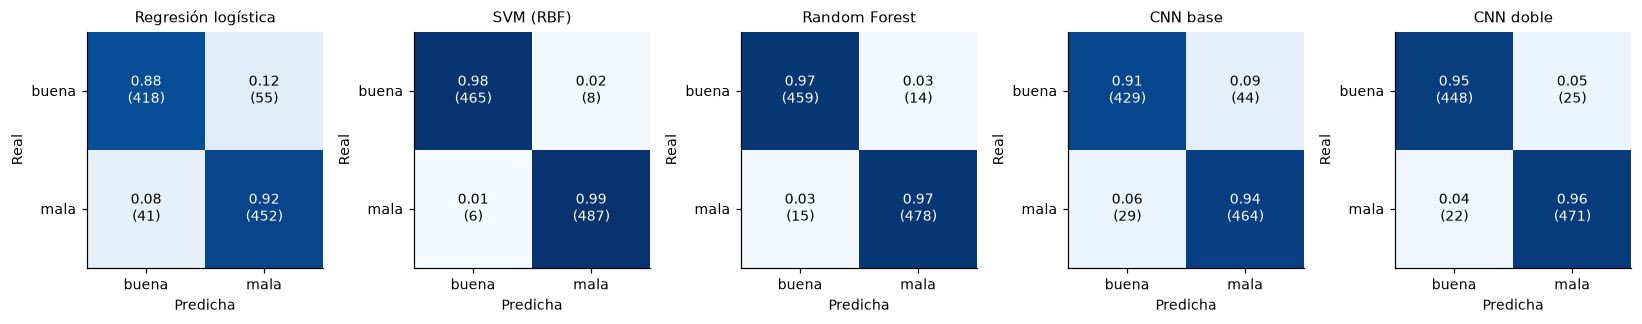

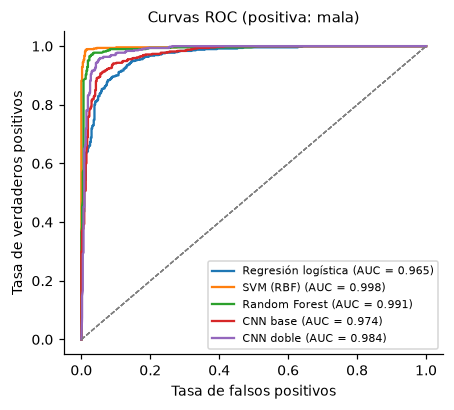

In [3]:
fig, axes = plt.subplots(1, len(modelos), figsize=(3 * len(modelos), 3))
for ax, (m, col) in zip(axes, modelos.items()):
    graficar_matriz_confusion(ax, pred["real"], pred[col], CLASES, NOMBRES[m])
fig.tight_layout()
guardar_figura(fig, "comparacion_matrices")
plt.show()

fig, ax = plt.subplots(figsize=(4.2, 3.8))
for m, col in modelos.items():
    p = pred[f"{col}_prob_{POS}"].to_numpy()
    graficar_roc(ax, pred["real"], np.column_stack([1 - p, p]), CLASES, NOMBRES[m])
ax.legend(fontsize=7, loc="lower right"); ax.set_title(f"Curvas ROC (positiva: {POS})", fontsize=10)
fig.tight_layout()
guardar_figura(fig, "comparacion_roc")
plt.show()

## 3. Desempeño por fruta

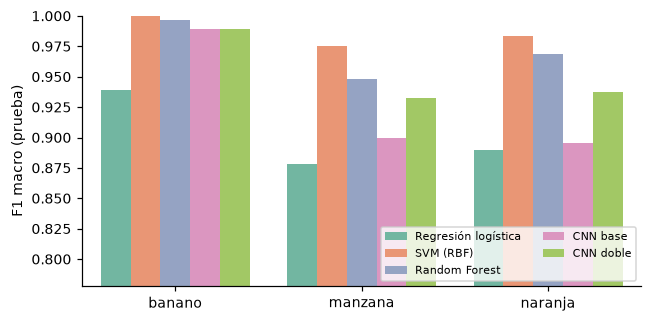

fruta,banano,manzana,naranja
modelo,,,
CNN base,0.9893,0.8992,0.8958
CNN doble,0.9893,0.9327,0.9378
Random Forest,0.9964,0.9482,0.9690
Regresión logística,0.9394,0.8779,0.8901
SVM (RBF),1.0000,0.9756,0.9831


In [4]:
por_fruta = pd.concat({NOMBRES[m]: metricas_por_grupo(pred, "fruta", CLASES, "real", col)
                       for m, col in modelos.items()}, names=["modelo"]).reset_index(level=0)
por_fruta.round(4).to_csv(RESULTADOS / "comparacion_por_fruta.csv", index=False)
fig, ax = plt.subplots(figsize=(6, 3))
sns.barplot(data=por_fruta, x="fruta", y="f1_macro", hue="modelo", ax=ax, palette="Set2")
ax.set_ylim(max(0, por_fruta["f1_macro"].min() - 0.1), 1); ax.set_xlabel(""); ax.set_ylabel("F1 macro (prueba)")
ax.legend(fontsize=7, ncol=2, loc="lower right")
fig.tight_layout()
guardar_figura(fig, "comparacion_por_fruta")
plt.show()
por_fruta.pivot(index="modelo", columns="fruta", values="f1_macro").round(4)

## 4. ¿La diferencia entre el mejor clásico y la CNN final es significativa?

Prueba de McNemar sobre las mismas 966 imágenes: solo cuentan los casos en que un modelo acierta y el otro no ($b$ y $c$). Con corrección de continuidad, $\chi^2 = (|b - c| - 1)^2 / (b + c)$, con un grado de libertad.

In [5]:
mejor_clasico = comp.loc[[NOMBRES[m] for m in ("logreg", "svm", "rf")], "f1_macro"].idxmax()
col_mc = modelos[{v: k for k, v in NOMBRES.items()}[mejor_clasico]]
acierto_a = pred[col_mc] == pred["real"]
acierto_b = pred[CNN_FINAL] == pred["real"]
b = int((acierto_a & ~acierto_b).sum()); c = int((~acierto_a & acierto_b).sum())
estad = (abs(b - c) - 1) ** 2 / (b + c) if b + c else 0.0
p_valor = float(chi2.sf(estad, 1))
mcnemar = {"modelo_a": mejor_clasico, "modelo_b": NOMBRES[CNN_FINAL], "solo_a_acierta": b, "solo_b_acierta": c,
           "ambos_fallan": int((~acierto_a & ~acierto_b).sum()), "chi2": round(estad, 3), "p_valor": round(p_valor, 4)}
(RESULTADOS / "mcnemar_clasico_vs_cnn.json").write_text(json.dumps(mcnemar, indent=2), encoding="utf8")
mcnemar

{'modelo_a': 'SVM (RBF)',
 'modelo_b': 'CNN doble',
 'solo_a_acierta': 34,
 'solo_b_acierta': 1,
 'ambos_fallan': 13,
 'chi2': 29.257,
 'p_valor': 0.0}

## 5. Sobreajuste: entrenamiento, validación y prueba

Para los clásicos, "entrenamiento" y "validación" son el F1 promedio de los pliegues de la validación cruzada con los mejores hiperparámetros; para las CNN, las particiones train y val.

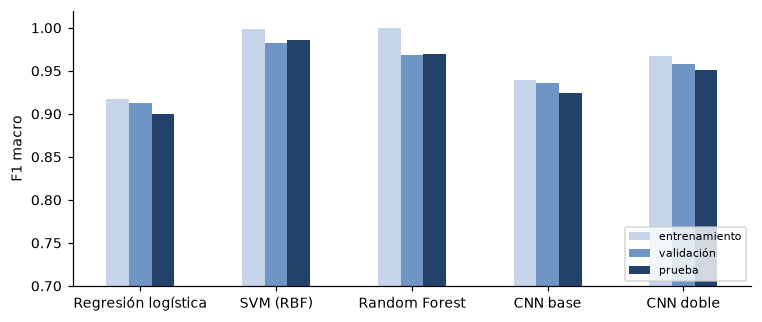

,entrenamiento,validacion,prueba,brecha_train_prueba
modelo,,,,
Regresión logística,0.9178,0.9131,0.9005,0.0173
SVM (RBF),0.9982,0.9824,0.9855,0.0127
Random Forest,1.0000,0.9680,0.9700,0.0300
CNN base,0.9393,0.9358,0.9243,0.0150
CNN doble,0.9671,0.9586,0.9513,0.0158


In [6]:
cv = pd.read_csv(RESULTADOS / "clasicos_cv_resumen.csv")
cnn_res = {v: json.loads(rutas_cnn(v)["resultados"].read_text(encoding="utf8")) for v in VARIANTES}
n_fruta = cargar_conjunto().query("particion != 'test'")["fruta"].value_counts()
filas = []
for m in ("logreg", "svm", "rf"):
    g = cv[(cv["configuracion"] == CFG) & (cv["modelo"] == m)]
    w = g["fruta"].map(n_fruta) if (g["fruta"] != "todas").all() else None
    filas.append({"modelo": NOMBRES[m], "entrenamiento": np.average(g["train_f1"], weights=w),
                  "validacion": np.average(g["cv_f1"], weights=w), "prueba": comp.loc[NOMBRES[m], "f1_macro"]})
for v, r in cnn_res.items():
    filas.append({"modelo": f"CNN {v}", "entrenamiento": r["train"]["f1_macro"],
                  "validacion": r["val"]["f1_macro"], "prueba": r["test"]["f1_macro"]})
sobre = pd.DataFrame(filas).set_index("modelo")
sobre["brecha_train_prueba"] = sobre["entrenamiento"] - sobre["prueba"]
sobre.round(4).to_csv(RESULTADOS / "comparacion_sobreajuste.csv")

fig, ax = plt.subplots(figsize=(7, 3))
sobre[["entrenamiento", "validacion", "prueba"]].plot.bar(ax=ax, color=["#c6d5ea", "#6f95c4", "#23426b"], rot=0)
ax.set_ylim(0.7, 1.02); ax.set_ylabel("F1 macro"); ax.set_xlabel("")
ax.legend(["entrenamiento", "validación", "prueba"], fontsize=7, loc="lower right")
fig.tight_layout()
guardar_figura(fig, "comparacion_sobreajuste")
plt.show()
sobre.round(4)

## 6. Tiempo de inferencia por imagen

Desde la imagen original hasta la predicción, que es lo que hará la app: leer, segmentar, recortar y (a) extraer características y clasificar o (b) pasar el recorte por la CNN. Se mide sobre 50 imágenes de prueba en la CPU de este equipo.

In [7]:
muestra = cargar_conjunto().query("particion == 'test'").sample(50, random_state=SEMILLA)
svm = joblib.load(CHECKPOINTS / f"clasico_{CFG}_svm.joblib")
cnn = keras.models.load_model(rutas_cnn(VARIANTE_FINAL)["modelo"])
cnn.predict(np.zeros((1, *TAM_IMAGEN, 3), np.float32), verbose=0)  # calentamiento

t_seg, t_feat, t_svm, t_cnn = [], [], [], []
for _, r in muestra.iterrows():
    t0 = time.perf_counter()
    img = leer_bgr(DATA_RAW_KAGGLE / r["ruta"])
    m = mascara_fruta(img)
    rec, rec_m = recorte_cuadrado(img, m)
    t1 = time.perf_counter()
    f = pd.DataFrame([extraer_caracteristicas(rec, rec_m)])
    if CFG == "global_fruta":
        for fr in ("manzana", "banano", "naranja"):
            f[f"fruta_{fr}"] = float(r["fruta"] == fr)
    t2 = time.perf_counter()
    if CFG == "por_fruta":
        modelo_svm = joblib.load(CHECKPOINTS / f"clasico_{CFG}_svm_{r['fruta']}.joblib")
    else:
        modelo_svm = svm
    modelo_svm.predict_proba(f)
    t3 = time.perf_counter()
    x = cv2.cvtColor(cv2.resize(rec, TAM_IMAGEN, interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)
    cnn(x[None].astype(np.float32), training=False)
    t4 = time.perf_counter()
    t_seg.append(t1 - t0); t_feat.append(t2 - t1); t_svm.append(t3 - t2); t_cnn.append(t4 - t3)
tiempos = pd.DataFrame({"segmentacion_y_recorte": t_seg, "caracteristicas": t_feat, "svm": t_svm, "cnn": t_cnn}) * 1000
resumen_t = tiempos.describe().loc[["mean", "50%", "max"]].round(1)
resumen_t.to_csv(RESULTADOS / "tiempos_inferencia_ms.csv")
print(f"Total SVM: {(tiempos['segmentacion_y_recorte'] + tiempos['caracteristicas'] + tiempos['svm']).mean():.0f} ms; "
      f"total CNN: {(tiempos['segmentacion_y_recorte'] + tiempos['cnn']).mean():.0f} ms (promedio)")
resumen_t

Total SVM: 223 ms; total CNN: 235 ms (promedio)


,segmentacion_y_recorte,caracteristicas,svm,cnn
mean,210.6,10.4,1.8,24.7
50%,193.6,10.0,1.8,24.0
max,627.9,16.5,2.0,42.5


## 7. Conclusiones de la evaluación interna

1. **Ranking en la prueba interna (F1 macro):** SVM 0,986 > Random Forest 0,970 > CNN doble 0,951 > CNN base 0,924 > regresión logística 0,901. La SVM también tiene el mejor recall de `mala` (0,988 [0,977; 0,996]) y el mejor AUC (0,998).
2. **La diferencia entre la SVM y la CNN doble es significativa.** En la prueba de McNemar, la SVM acierta 34 imágenes que la CNN falla y la CNN solo 1 que la SVM falla ($\chi^2 = 29{,}3$, $p < 0{,}001$).
3. **El desempeño depende de la fruta.** Banano es casi perfecto para todos los modelos (la SVM acierta todo); manzana es la más difícil (SVM 0,976, CNN 0,933) por la confusión entre variedad roja y daño.
4. **Ningún modelo muestra sobreajuste dañino.** La brecha entre entrenamiento y prueba va de 0,013 (SVM) a 0,030 (Random Forest).
5. **Tiempo de inferencia por imagen**, desde el archivo hasta la predicción, en la CPU de este equipo: unos 220 ms con la SVM y 235 ms con la CNN. La segmentación con GrabCut ocupa unos 200 ms. Ambos cumplen el criterio de éxito de menos de 2 s.
6. **Modelo propuesto para la app: la SVM `global_fruta`**, con la CNN doble como comparación.

**Cautela.** Estos números son de la prueba **interna**, que comparte los sesgos del dataset: las condiciones de captura solas predicen la calidad con F1 ≈ 0,95 (notebook 03), la variedad de manzana está correlacionada con la etiqueta y el banano casi perfecto sugiere que la tarea en este dataset es más fácil que en la realidad. La conclusión sobre qué modelo generaliza mejor se decide con las fotos propias (fase 3 del plan). Allí puede cambiar el orden, porque la CNN y la SVM se apoyan en señales distintas.